In [1]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt # plotting
import numpy as np # linear algebra
import os # accessing directory structure
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
sns.set_theme(palette="colorblind")

In [2]:
df_train = pd.read_csv("../data/datatraining.txt")
df_test1 = pd.read_csv("../data/datatest.txt")
df_test2 = pd.read_csv("../data/datatest2.txt")
df1 = pd.concat([df_train,df_test1,df_test2])
nRow, nCol = df1.shape
print(f'There are {nRow} rows and {nCol} columns')

# Parse timestamps before performing time-based feature engineering
df1['date'] = pd.to_datetime(df1['date'], errors='coerce')

# Remove rows whose timestamp could not be parsed
df1 = df1.dropna(subset=['date']).copy()

# Number of seconds elapsed since midnight (0 to 86399)
df1['NSM'] = (
    df1['date'].dt.hour * 3600
    + df1['date'].dt.minute * 60
    + df1['date'].dt.second
)

# Boolean calendar features
df1['Weekday'] = (df1['date'].dt.dayofweek < 5)
df1['Weekend'] = (df1['date'].dt.dayofweek >= 5)

print(df1[['date', 'NSM', 'Weekday', 'Weekend']].head())
print('Invalid dates removed:', nRow - len(df1))

There are 20560 rows and 7 columns
                 date    NSM  Weekday  Weekend
1 2015-02-04 17:51:00  64260     True    False
2 2015-02-04 17:51:59  64319     True    False
3 2015-02-04 17:53:00  64380     True    False
4 2015-02-04 17:54:00  64440     True    False
5 2015-02-04 17:55:00  64500     True    False
Invalid dates removed: 0


In [3]:
df1.describe()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,NSM
count,20560,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000
mean,2015-02-10 13:42:06.146984448,20.906212,27.655925,130.756622,690.553276,0.004228,0.231031,42997.431031
min,2015-02-02 14:19:00,19.000000,16.745000,0.000000,412.750000,0.002674,0.000000,0.000000
25%,2015-02-06 11:05:45,20.200000,24.500000,0.000000,460.000000,0.003719,0.000000,20520.000000
50%,2015-02-10 00:45:30,20.700000,27.290000,0.000000,565.416667,0.004292,0.000000,42480.000000
75%,2015-02-14 19:39:14.249999872,21.525000,31.290000,301.000000,804.666667,0.004832,0.000000,65819.000000
max,2015-02-18 09:19:00,24.408333,39.500000,1697.250000,2076.500000,0.006476,1.000000,86339.000000
std,NaN,1.055315,4.982154,210.430875,311.201281,0.000768,0.421503,25497.938212


In [4]:
df1.head(5)

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,NSM,Weekday,Weekend
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1,64260,True,False
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1,64319,True,False
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1,64380,True,False
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1,64440,True,False
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1,64500,True,False


In [5]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20560 entries, 1 to 9752
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           20560 non-null  datetime64[ns]
 1   Temperature    20560 non-null  float64       
 2   Humidity       20560 non-null  float64       
 3   Light          20560 non-null  float64       
 4   CO2            20560 non-null  float64       
 5   HumidityRatio  20560 non-null  float64       
 6   Occupancy      20560 non-null  int64         
 7   NSM            20560 non-null  int32         
 8   Weekday        20560 non-null  bool          
 9   Weekend        20560 non-null  bool          
dtypes: bool(2), datetime64[ns](1), float64(5), int32(1), int64(1)
memory usage: 1.4 MB


In [6]:
for col in df1.columns:
    print("No.of na for ",col , ": ",df1[col].isna().sum())

No.of na for  date :  0
No.of na for  Temperature :  0
No.of na for  Humidity :  0
No.of na for  Light :  0
No.of na for  CO2 :  0
No.of na for  HumidityRatio :  0
No.of na for  Occupancy :  0
No.of na for  NSM :  0
No.of na for  Weekday :  0
No.of na for  Weekend :  0


In [7]:
features = ["Temperature","Light","CO2","HumidityRatio"]

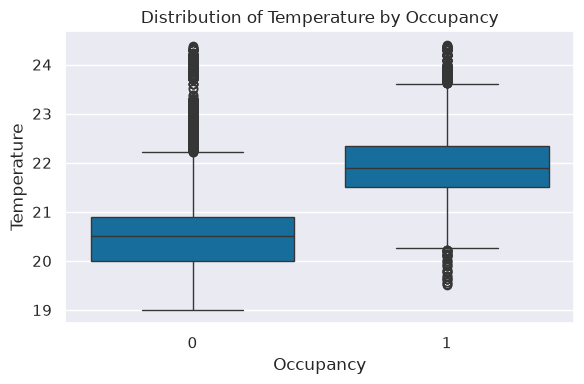

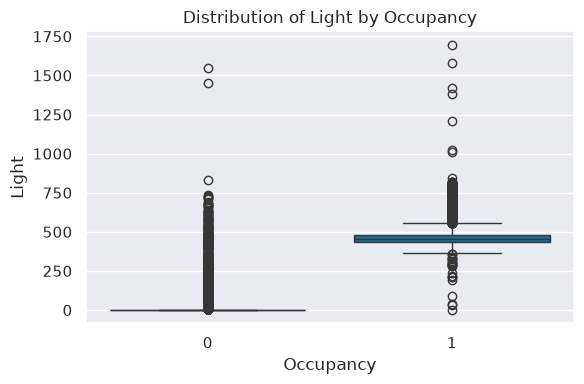

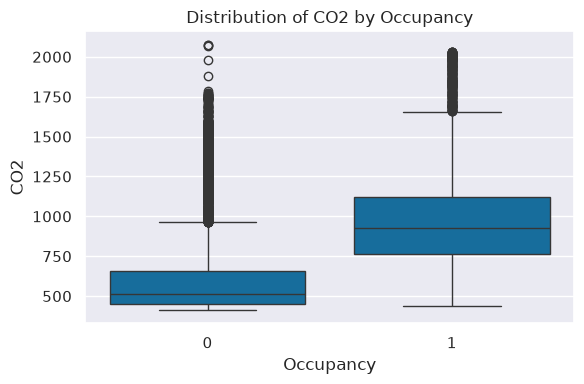

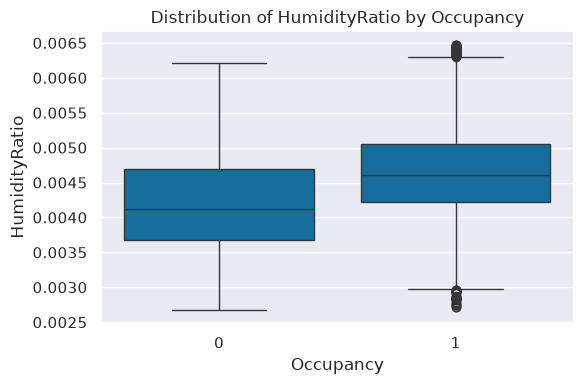

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define your feature columns explicitly (excluding target column)
features = ['Temperature', 'Light', 'CO2', 'HumidityRatio']

for col in features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df1, x='Occupancy', y=col)
    plt.title(f'Distribution of {col} by Occupancy')
    plt.tight_layout()
    plt.show()

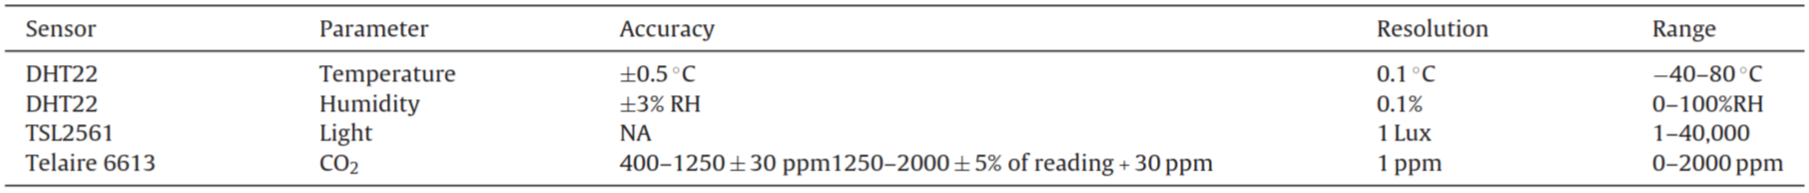
Sensors used to record 

Using the hardware specification, we note that the CO2 recodings, over 2000 are considered to be sensor anamolies hence we would be removing those records

<Axes: xlabel='Occupancy', ylabel='Count'>

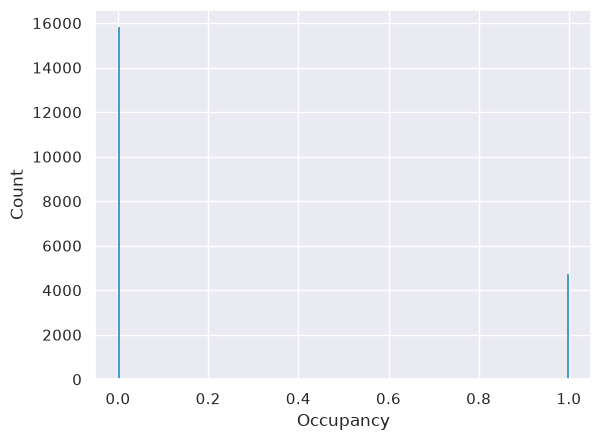

In [9]:
sns.histplot(df1.Occupancy)

This shows class imbalance

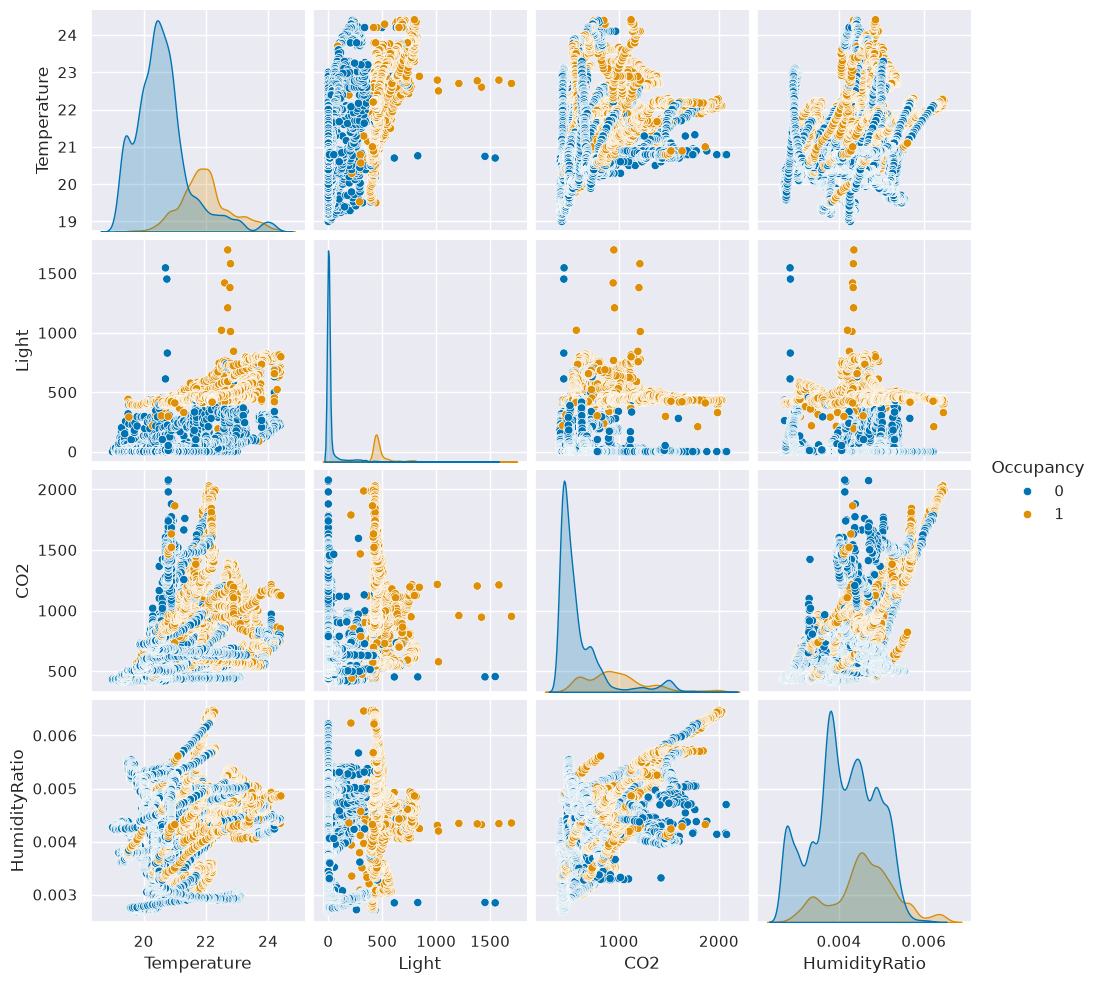

In [11]:
sns.pairplot(df1[features+["Occupancy"]],hue='Occupancy')

<Axes: >

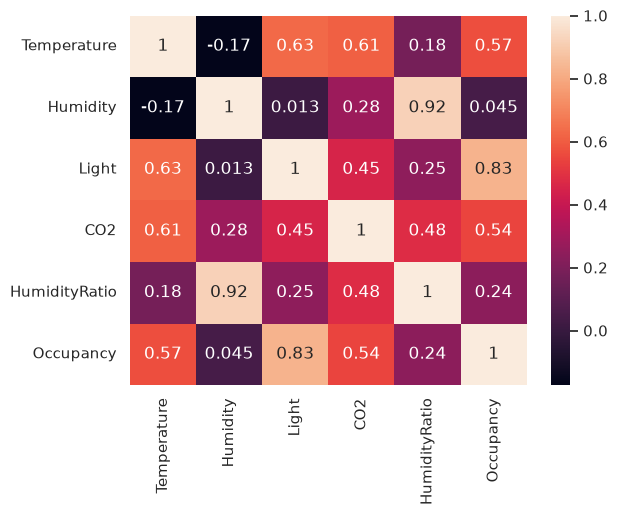

In [15]:
sns.heatmap(df1[["Temperature","Humidity","Light","CO2","HumidityRatio","Occupancy"]].corr(method='spearman'),annot=True)

In [16]:
features = ["Temperature","Humidity","Light","CO2","HumidityRatio"]
print(df1.groupby("Occupancy")[features].mean())
print(df1.groupby("Occupancy")[features].median())


           Temperature   Humidity       Light         CO2  HumidityRatio
Occupancy                                                               
0            20.584830  27.529654   25.237893  604.996614       0.004120
1            21.975909  28.076209  481.967380  975.321870       0.004589
           Temperature  Humidity  Light         CO2  HumidityRatio
Occupancy                                                         
0                20.50    27.150    0.0  511.000000       0.004127
1                21.89    27.882  454.0  928.583333       0.004603


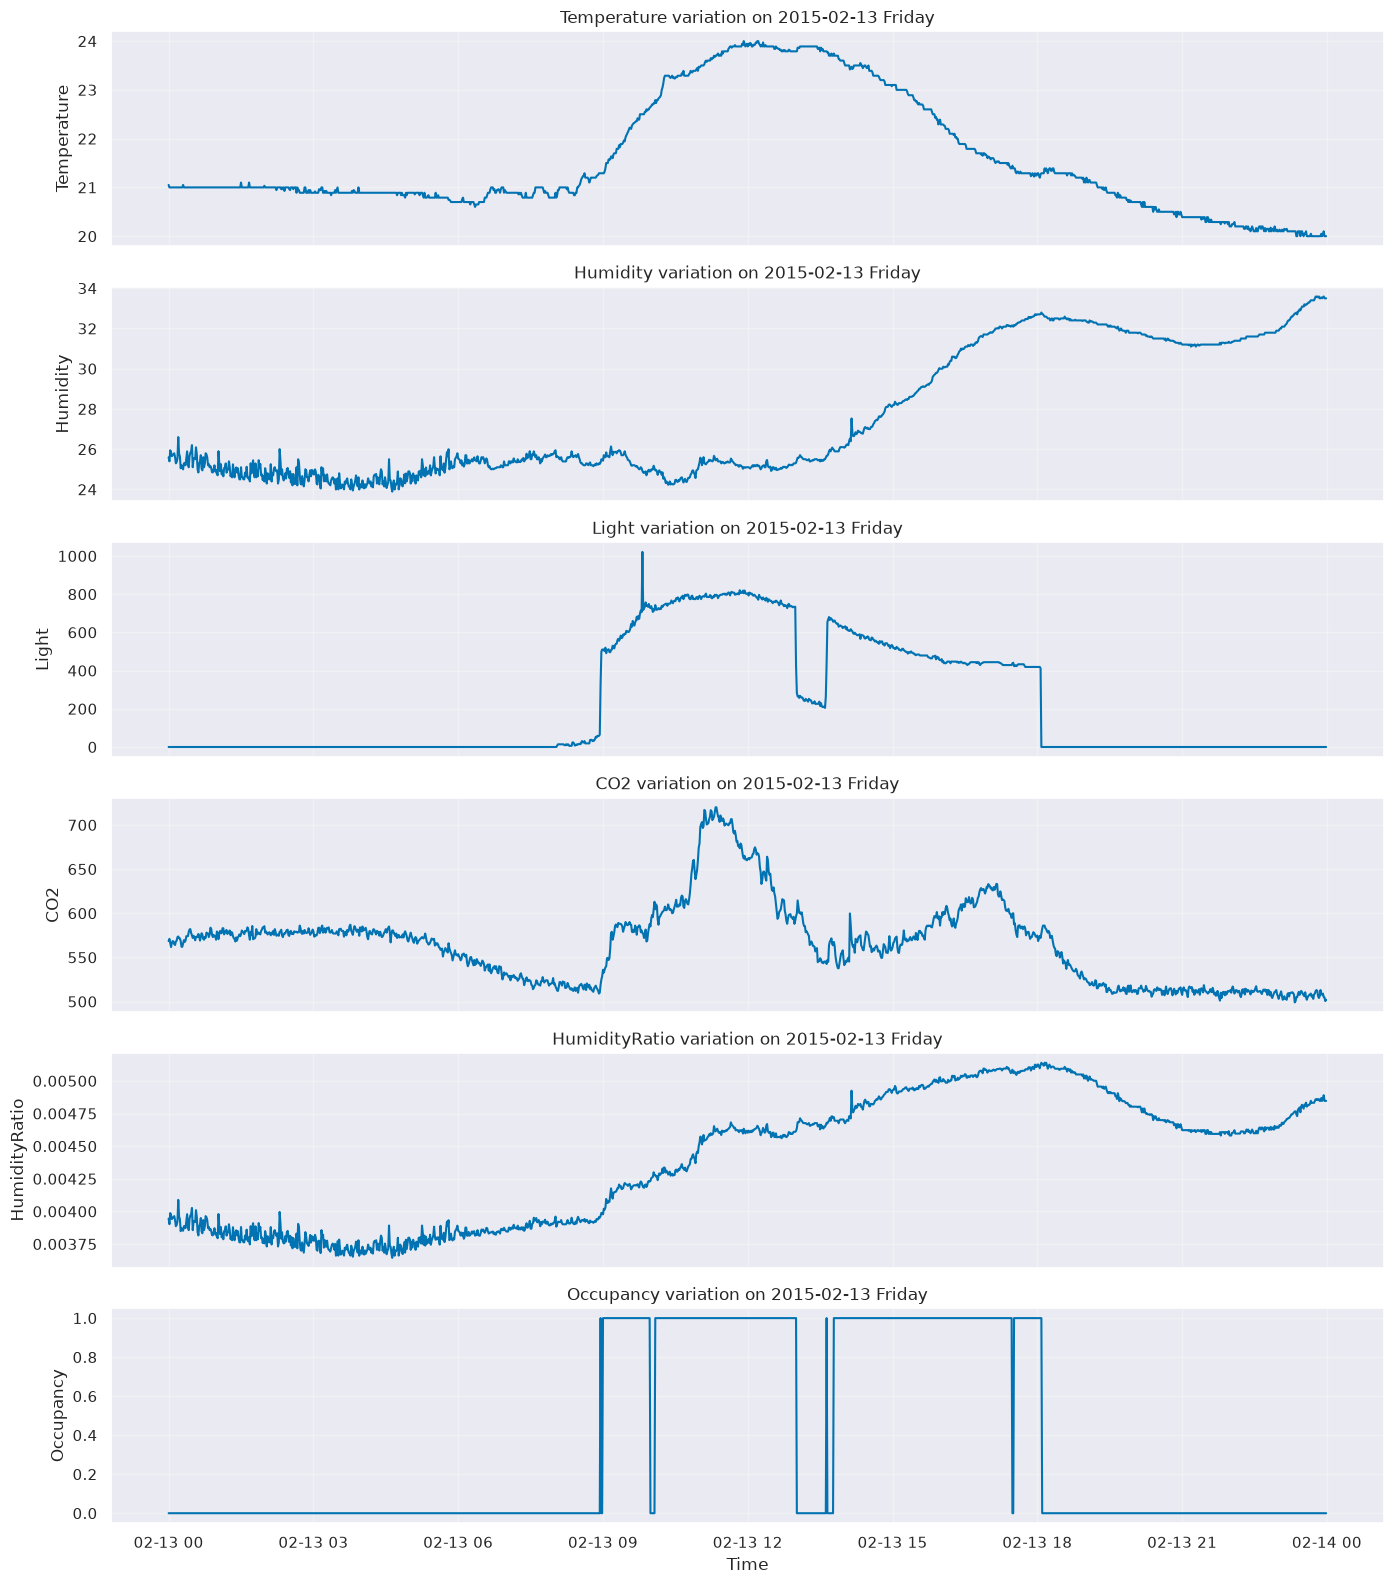

In [17]:
features = [
      "Temperature",
      "Humidity",
      "Light",
      "CO2",
      "HumidityRatio",
      "Occupancy"
  ]
df1["date"] = pd.to_datetime(df1["date"])

  # Select a specific date
selected_date = "2015-02-13"

day_data = df1[
  df1["date"].dt.date == pd.to_datetime(selected_date).date()
].copy()
  # Plot each feature against time
fig, axes = plt.subplots(
  len(features),
  1,
  figsize=(14, 16),
  sharex=True
)

for ax, feature in zip(axes, features):
  ax.plot(
      day_data["date"],
      day_data[feature],
      linewidth=1.5
  )
  ax.set_title(f"{feature} variation on {selected_date} "+ pd.to_datetime(selected_date).day_name())
  ax.set_ylabel(feature)
  ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

This plot visualaises the change of features on given date.
We are able to notice the fluctuation of the light, w.r.t to occupancy 

## Distribution of Temperature

<Axes: xlabel='Temperature', ylabel='Count'>

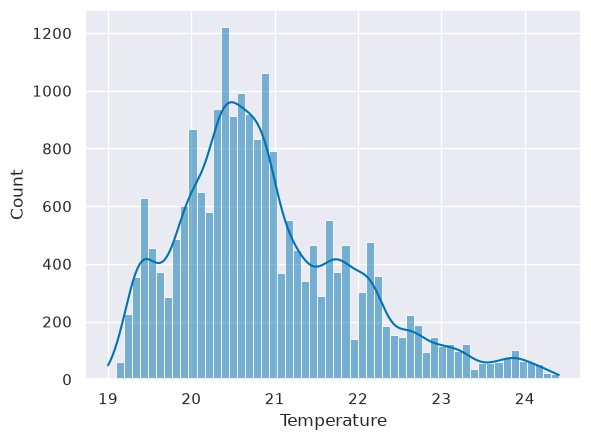

In [18]:
sns.histplot(df1.Temperature,kde=True)

## Distribution of Humidity Ratio

<Axes: xlabel='HumidityRatio', ylabel='Count'>

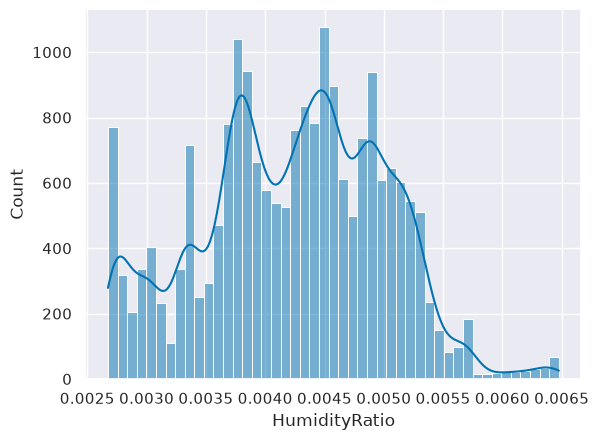

In [19]:
sns.histplot(df1.HumidityRatio,kde=True)

# Distribution of Light

<Axes: xlabel='Light', ylabel='Count'>

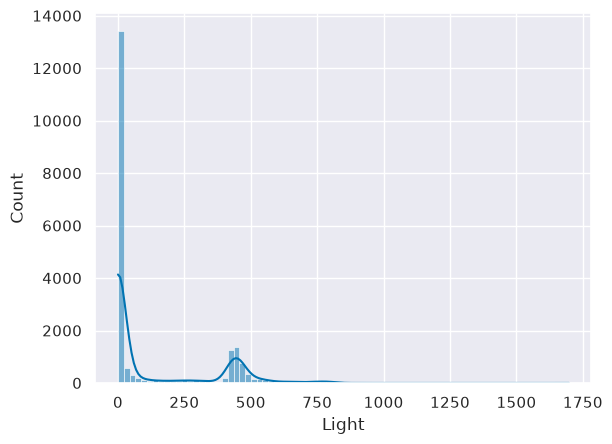

In [20]:
sns.histplot(df1.Light,kde=True)


# Distribution of CO2

<Axes: xlabel='CO2', ylabel='Count'>

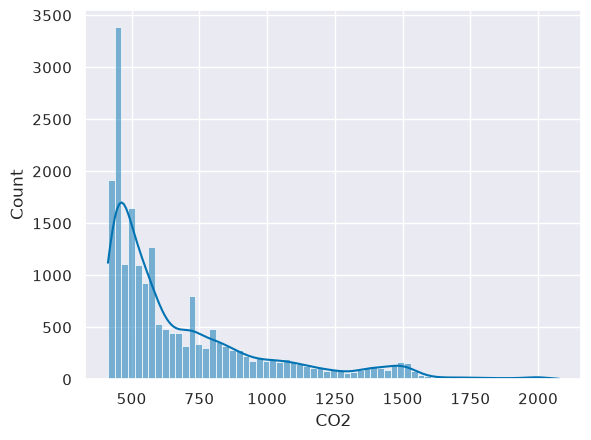

In [21]:
sns.histplot(df1.CO2,kde=True)

# Distribution of Temperature

<Axes: xlabel='Temperature', ylabel='Count'>

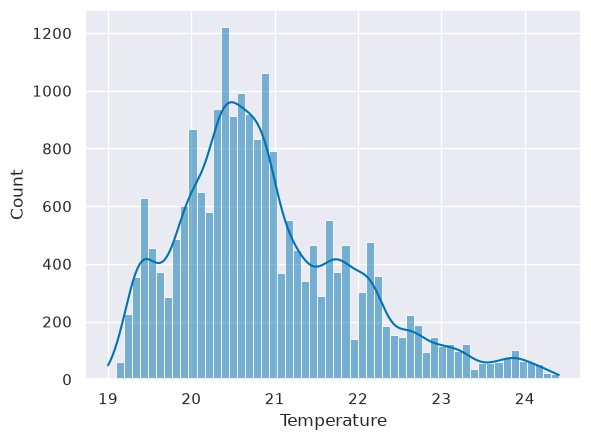

In [22]:
sns.histplot(df1.Temperature,kde=True)

# Feature Engineering

> Humidity ratio is also feature engineered by the dataset provider. This is used over humidity, to make humidity independent of temperature.
> This is calculated as <br>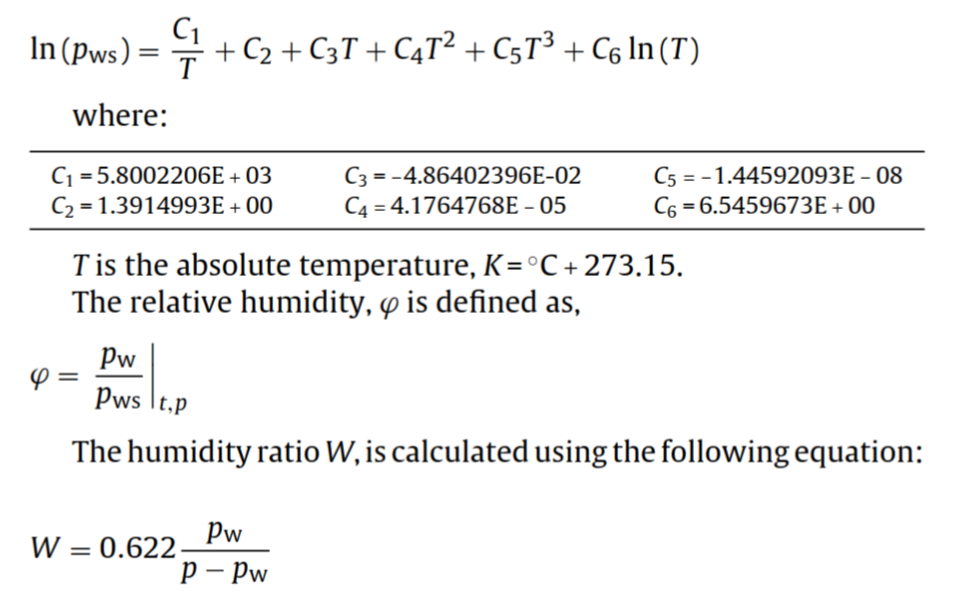

In [23]:
df1["date"] = pd.to_datetime(df1["date"])

# Seconds since midnight
df1["NSM"] = (
  df1["date"].dt.hour * 3600
  + df1["date"].dt.minute * 60
  + df1["date"].dt.second
)

# True for Monday–Friday, False for Saturday–Sunday
df1["Weekday"] = df1["date"].dt.dayofweek < 5

# True for Saturday–Sunday, False otherwise
df1["Weekend"] = df1["date"].dt.dayofweek >= 5

df1[["date", "NSM", "Weekday", "Weekend"]].head()

,date,NSM,Weekday,Weekend
1,2015-02-04 17:51:00,64260,True,False
2,2015-02-04 17:51:59,64319,True,False
3,2015-02-04 17:53:00,64380,True,False
4,2015-02-04 17:54:00,64440,True,False
5,2015-02-04 17:55:00,64500,True,False


# Training the model

In [32]:
from sklearn.model_selection import train_test_split
target = "Occupancy"
features = [
  "Temperature",
  "Light",
  "CO2",
  "HumidityRatio",
  "NSM",
  "Weekday",
  "Weekend"
]
# Select required columns and remove missing values
model_data = df1[features + [target]].dropna().copy()

# Convert Boolean features to integers
model_data["Weekday"] = model_data["Weekday"].astype(int)
model_data["Weekend"] = model_data["Weekend"].astype(int)

X = model_data[features]
y = model_data[target]

# Stratified split because the classes are imbalanced
X_train, X_test, y_train, y_test = train_test_split(
  X,
  y,
  test_size=0.25,
  random_state=42,
  stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))

Training set: (15420, 7)
Testing set: (5140, 7)

Training class distribution:
Occupancy
0    0.768936
1    0.231064
Name: proportion, dtype: float64


=== Logistic Regression ===
Best Params: {'clf__C': 1.0, 'clf__solver': 'lbfgs'}
Test Accuracy: 0.9899

=== K-Nearest Neighbors ===
Best Params: {'clf__metric': 'manhattan', 'clf__n_neighbors': 3}
Test Accuracy: 0.9926

=== Naive Bayes (Gaussian) ===
Best Params: {'clf__var_smoothing': np.float64(0.01)}
Test Accuracy: 0.9765

=== Decision Tree ===
Best Params: {'clf__criterion': 'entropy', 'clf__max_depth': 10}
Test Accuracy: 0.9914

=== Support Vector Machine ===
Best Params: {'clf__C': 10.0, 'clf__kernel': 'linear'}
Test Accuracy: 0.9905

=== Logistic Regression Coefficients & Odds Ratios ===
      Feature  Log-Odds (Coef)  Odds Ratio
        Light         6.272751  529.933342
      Weekday         3.226659   25.195346
          NSM         0.926816    2.526451
HumidityRatio         0.750101    2.117213
          CO2         0.607019    1.834954
  Temperature        -1.219680    0.295325
      Weekend        -3.226659    0.039690


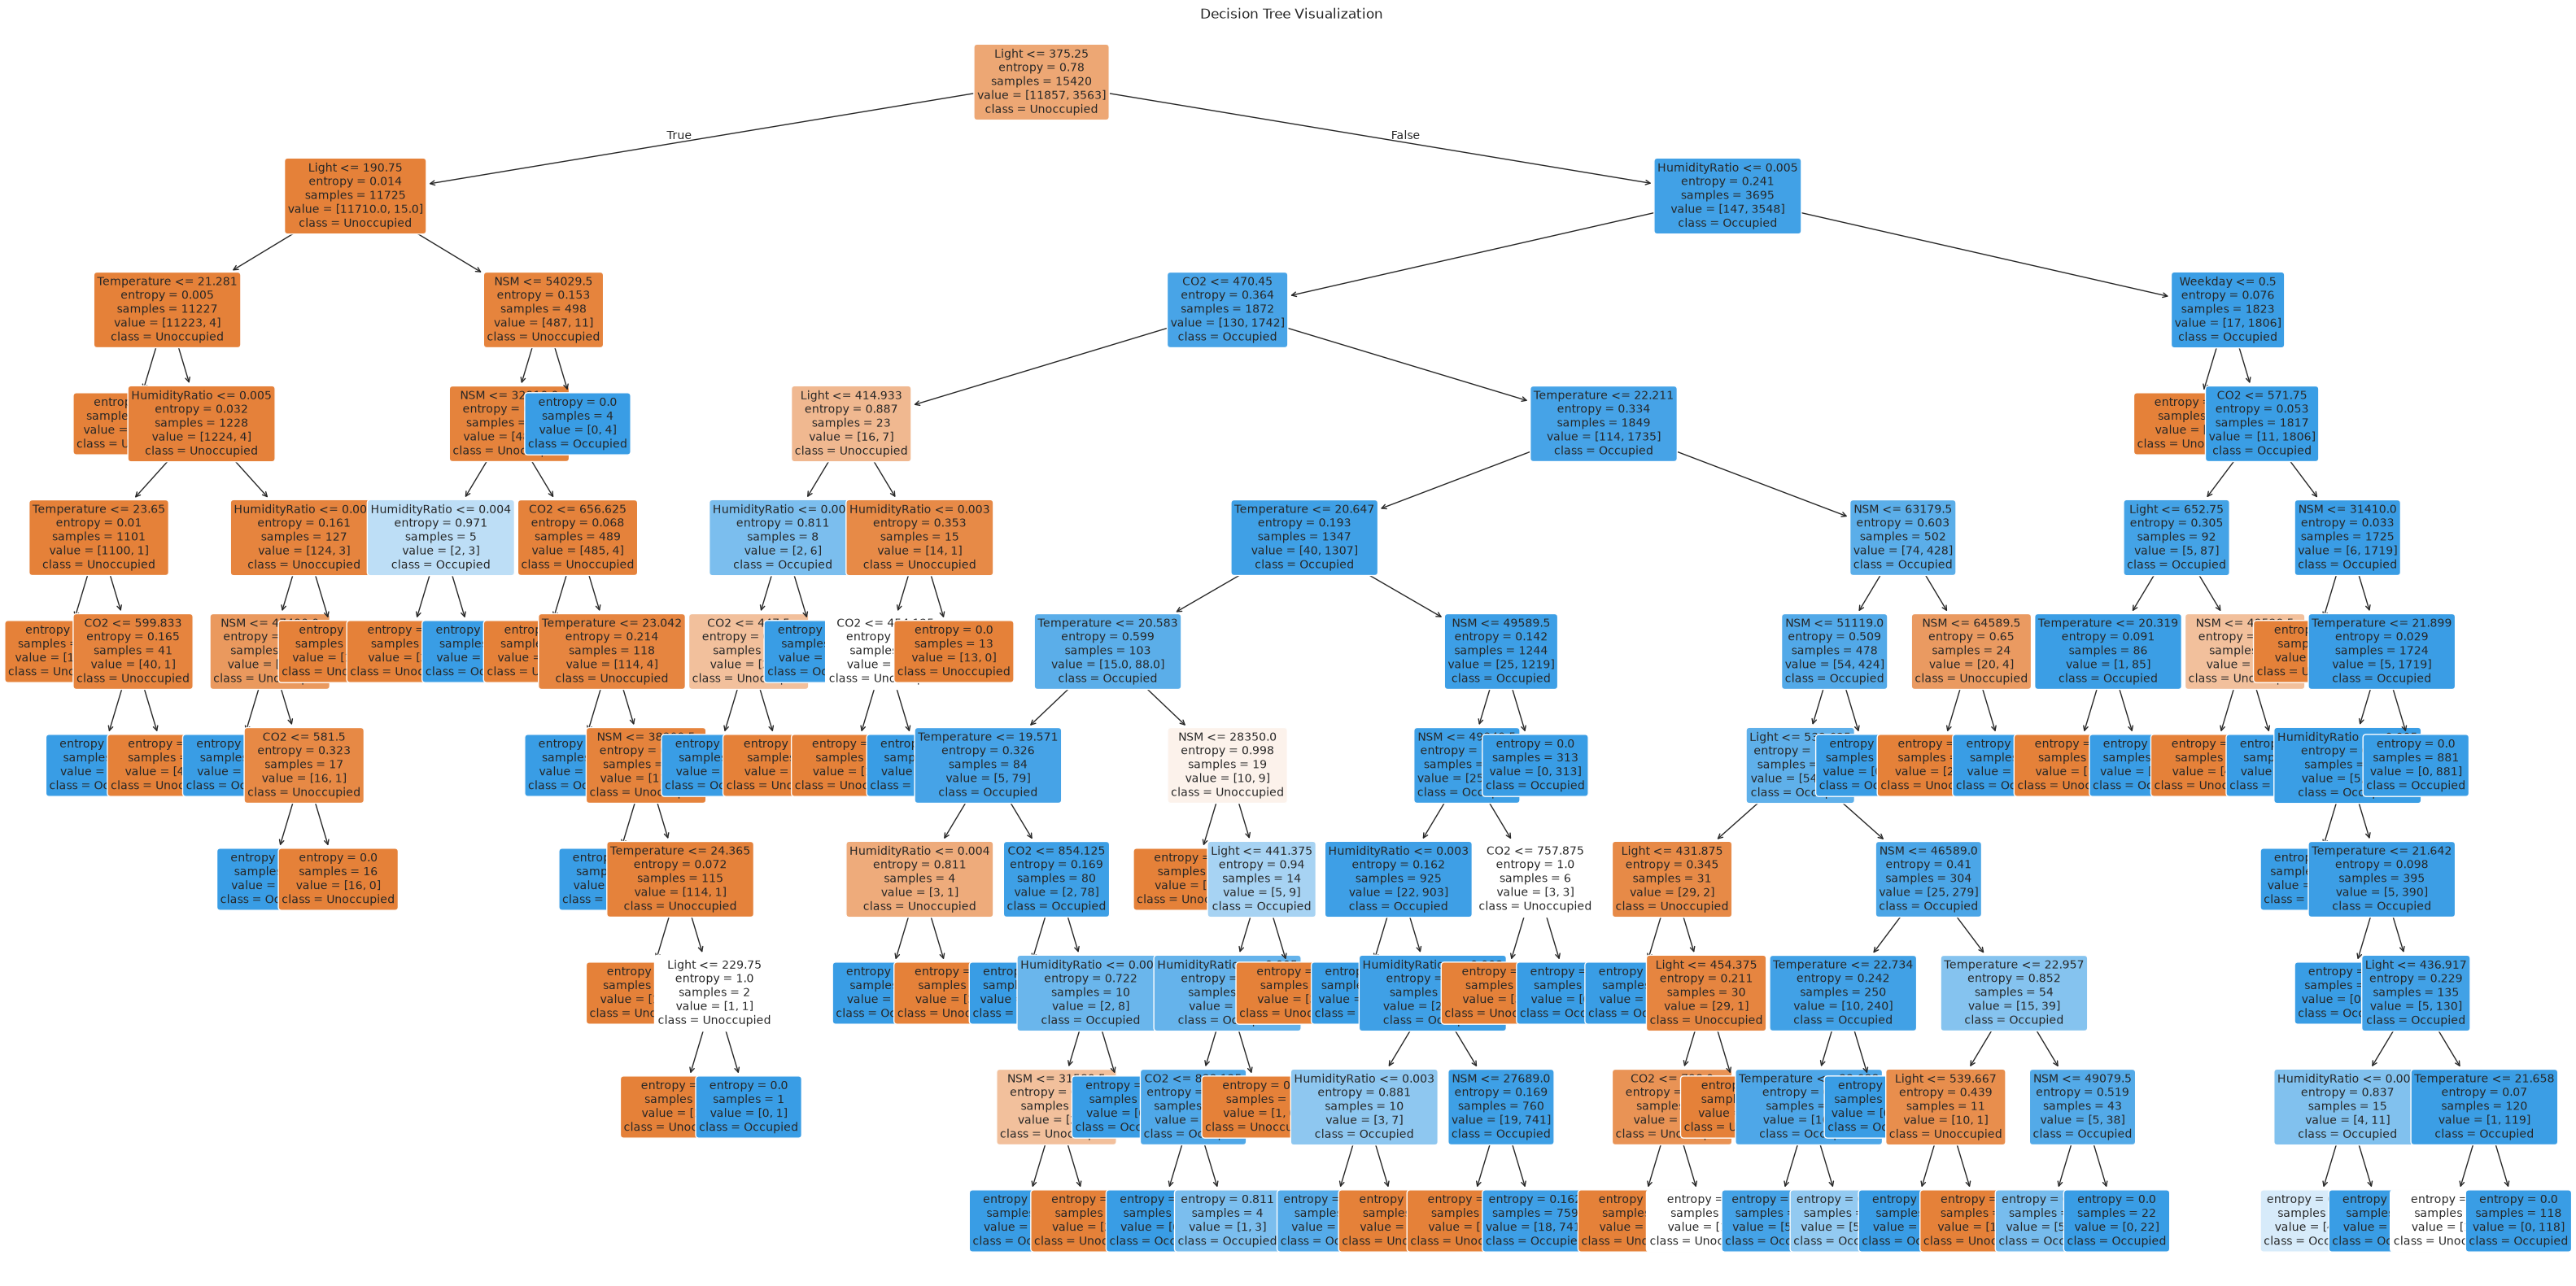

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

# -------------------------------------------------------------------
# 1. Pipeline & Model Definitions
# -------------------------------------------------------------------

# Logistic Regression (Baseline classifier)
pipe_logreg = Pipeline([
    ('scaler', RobustScaler()),
    ('clf', LogisticRegression(random_state=42, max_iter=1000))
])

# K-Nearest Neighbors (Tune k & metric)
pipe_knn = Pipeline([
    ('scaler', RobustScaler()), # Critical: distance metrics depend on scaling
    ('clf', KNeighborsClassifier())
])

# Gaussian Naive Bayes
pipe_gnb = Pipeline([
    ('scaler', RobustScaler()),
    ('clf', GaussianNB())
])

# Decision Tree (Tune max_depth)
# Scaling is optional for trees, omitted to keep raw feature splits clean
pipe_dt = Pipeline([
    ('clf', DecisionTreeClassifier(random_state=42))
])

# Support Vector Classifier (Tune C & kernel)
pipe_svc = Pipeline([
    ('scaler', RobustScaler()), # Critical for boundary margins
    ('clf', SVC(random_state=42))
])

# -------------------------------------------------------------------
# 2. Hyperparameter Grids
# -------------------------------------------------------------------

param_grids = {
    "Logistic Regression": {
        'clf__C': [0.01, 0.1, 1.0, 10.0],
        'clf__solver': ['lbfgs']
    },
    "K-Nearest Neighbors": {
        'clf__n_neighbors': [1,3, 5, 7, 11, 15,17,19],
        'clf__metric': ['euclidean', 'manhattan']
    },
    "Naive Bayes (Gaussian)": {
        'clf__var_smoothing': np.logspace(0, -9, num=10)
    },
    "Decision Tree": {
        'clf__max_depth': [3, 5, 7, 10, None],
        'clf__criterion': ['gini', 'entropy']
    },
    "Support Vector Machine": {
        'clf__C': [0.1, 1.0, 10.0],
        'clf__kernel': ['rbf', 'linear', 'poly']
    }
}

pipelines = {
    "Logistic Regression": pipe_logreg,
    "K-Nearest Neighbors": pipe_knn,
    "Naive Bayes (Gaussian)": pipe_gnb,
    "Decision Tree": pipe_dt,
    "Support Vector Machine": pipe_svc
}

# -------------------------------------------------------------------
# 3. Training & Evaluation Loop (Replace X_train, X_test, y_train, y_test)
# -------------------------------------------------------------------

best_models = {}

for name, pipe in pipelines.items():
    grid = GridSearchCV(
        estimator=pipe, 
        param_grid=param_grids[name], 
        cv=5, 
        scoring='accuracy', 
        n_jobs=-1
    )
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_
    
    # Test Evaluation
    y_pred = grid.predict(X_test)
    print(f"=== {name} ===")
    print(f"Best Params: {grid.best_params_}")
    print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")

# -------------------------------------------------------------------
# 4. Model-Specific Requirements & Interpretations
# -------------------------------------------------------------------

# A. Logistic Regression: Coefficient Interpretation[cite: 3]
logreg_clf = best_models["Logistic Regression"].named_steps['clf']
feature_names = X_train.columns
odds_ratios = np.exp(logreg_clf.coef_[0])

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Log-Odds (Coef)': logreg_clf.coef_[0],
    'Odds Ratio': odds_ratios
}).sort_values(by='Odds Ratio', ascending=False)

print("=== Logistic Regression Coefficients & Odds Ratios ===")
print(coef_df.to_string(index=False))

# B. Decision Tree: Tree Visualization[cite: 3]
plt.figure(figsize=(40, 20))
dt_clf = best_models["Decision Tree"].named_steps['clf']
plot_tree(
    dt_clf, 
    feature_names=X_train.columns, 
    class_names=['Unoccupied', 'Occupied'], 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.show()